In [34]:
print("Linear Regression from Scratch using NumPy")
print("My first Machine Learning internship project!")

Linear Regression from Scratch using NumPy
My first Machine Learning internship project!
The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Libraries imported successfully!")

NumPy version: 2.1.3
Pandas version: 2.2.3
Libraries imported successfully!


In [6]:
# Separate numerical features and target
X = df.drop(columns=["median_house_value", "ocean_proximity"])
y = df["median_house_value"]

# Fill missing values using the median of each feature
X = X.fillna(X.median())

# Convert to NumPy arrays
X = X.to_numpy(dtype=float)
y = y.to_numpy(dtype=float)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Missing values remaining:", np.isnan(X).sum())

Features shape: (20640, 8)
Target shape: (20640,)
Missing values remaining: 0


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)
Training targets: (16512,)
Testing targets: (4128,)


In [8]:
# Calculate mean and standard deviation from training data only
X_mean = np.mean(X_train, axis=0)
X_std = np.std(X_train, axis=0)

# Avoid division by zero if a feature has zero variance
X_std[X_std == 0] = 1

# Standardize training and test features
X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

print("Training feature means (approximately 0):")
print(np.round(np.mean(X_train_scaled, axis=0), 4))

print("\nTraining feature standard deviations (approximately 1):")
print(np.round(np.std(X_train_scaled, axis=0), 4))

print("\nScaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Training feature means (approximately 0):
[-0.  0. -0.  0. -0. -0. -0. -0.]

Training feature standard deviations (approximately 1):
[1. 1. 1. 1. 1. 1. 1. 1.]

Scaled training shape: (16512, 8)
Scaled testing shape: (4128, 8)


In [10]:
def hypothesis(X, theta):
    """
    Predict target values using linear regression.

    X: feature matrix of shape (m, n)
    theta: parameter vector of shape (n + 1,)
    """
    # Add a column of ones for the bias term
    X_with_bias = np.c_[np.ones(X.shape[0]), X]

    # Calculate predictions using matrix multiplication
    predictions = X_with_bias @ theta

    return predictions

In [11]:
# Two samples, each with one feature
X_demo = np.array([[2], [3]], dtype=float)

# Bias = 1, weight = 4
theta_demo = np.array([1, 4], dtype=float)

predictions_demo = hypothesis(X_demo, theta_demo)

print("Predictions:", predictions_demo)

Predictions: [ 9. 13.]


In [12]:
def compute_cost(y_actual, y_predicted):
    """
    Calculate Mean Squared Error (MSE).

    y_actual: actual target values
    y_predicted: predicted target values
    """
    errors = y_predicted - y_actual
    mse = np.mean(errors ** 2)

    return mse

In [13]:
y_actual_demo = np.array([3, 5, 7], dtype=float)
y_predicted_demo = np.array([2, 5, 9], dtype=float)

cost_demo = compute_cost(y_actual_demo, y_predicted_demo)

print("MSE:", cost_demo)

MSE: 1.6666666666666667


In [15]:
def gradient_descent(X, y, learning_rate=0.01, iterations=1000):
    """
    Train linear regression using batch gradient descent.

    X: standardized feature matrix, shape (m, n)
    y: target values, shape (m,)
    """
    m, n = X.shape

    # Add the bias column
    X_with_bias = np.c_[np.ones(m), X]

    # Initialize all parameters to zero
    theta = np.zeros(n + 1)

    # Store the cost at each iteration
    cost_history = []

    for i in range(iterations):
        # Calculate predictions
        predictions = X_with_bias @ theta

        # Calculate prediction errors
        errors = predictions - y

        # Calculate gradients for all parameters
        gradients = (X_with_bias.T @ errors) / m

        # Update parameters
        theta = theta - learning_rate * gradients

        # Calculate and store the updated cost
        updated_predictions = X_with_bias @ theta
        cost = compute_cost(y, updated_predictions)
        cost_history.append(cost)

    return theta, cost_history

In [16]:
# Calculate mean and standard deviation from training targets only
y_mean = np.mean(y_train)
y_std = np.std(y_train)

# Standardize training and test targets
y_train_scaled = (y_train - y_mean) / y_std
y_test_scaled = (y_test - y_mean) / y_std

print("Training target mean:", round(np.mean(y_train_scaled), 4))
print("Training target standard deviation:", round(np.std(y_train_scaled), 4))
print("Training target shape:", y_train_scaled.shape)
print("Testing target shape:", y_test_scaled.shape)

Training target mean: -0.0
Training target standard deviation: 1.0
Training target shape: (16512,)
Testing target shape: (4128,)


In [17]:
# Train the model using gradient descent
theta, cost_history = gradient_descent(
    X_train_scaled,
    y_train_scaled,
    learning_rate=0.01,
    iterations=1000
)

print("Training completed!")
print("Initial cost:", cost_history[0])
print("Final cost:", cost_history[-1])
print("Number of parameters:", len(theta))

Training completed!
Initial cost: 0.9893501591396571
Final cost: 0.382291281329761
Number of parameters: 9


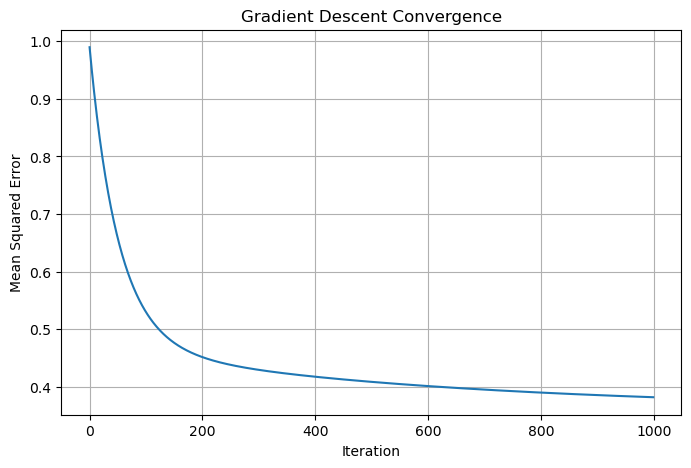

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(cost_history)

plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Convergence")
plt.grid(True)

plt.show()

In [19]:
# Generate predictions on the scaled test features
y_pred_scaled = hypothesis(X_test_scaled, theta)

# Convert predictions back to original house-price units
y_pred = y_pred_scaled * y_std + y_mean

# Calculate test MSE manually
test_mse = np.mean((y_test - y_pred) ** 2)

# Calculate R² manually
ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

test_r2 = 1 - (ss_res / ss_tot)

print(f"Test MSE: {test_mse:.2f}")
print(f"Test RMSE: {np.sqrt(test_mse):.2f}")
print(f"Test R²: {test_r2:.4f}")

Test MSE: 5271401486.73
Test RMSE: 72604.42
Test R²: 0.5977


In [20]:
from sklearn.linear_model import LinearRegression

# Train scikit-learn's model on the same standardized features
sk_model = LinearRegression()
sk_model.fit(X_train_scaled, y_train_scaled)

# Predict and convert to original house-price units
sk_pred_scaled = sk_model.predict(X_test_scaled)
sk_pred = sk_pred_scaled * y_std + y_mean

# Calculate metrics manually
sk_mse = np.mean((y_test - sk_pred) ** 2)

sk_ss_res = np.sum((y_test - sk_pred) ** 2)
sk_ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
sk_r2 = 1 - sk_ss_res / sk_ss_tot

# Compare the two models
print("FROM-SCRATCH MODEL")
print(f"MSE:  {test_mse:.2f}")
print(f"R²:   {test_r2:.6f}")

print("\nSCIKIT-LEARN MODEL")
print(f"MSE:  {sk_mse:.2f}")
print(f"R²:   {sk_r2:.6f}")

print("\nCOMPARISON")
print(f"Absolute MSE difference: {abs(test_mse - sk_mse):.2f}")
print(f"Absolute R² difference:  {abs(test_r2 - sk_r2):.6f}")

FROM-SCRATCH MODEL
MSE:  5271401486.73
R²:   0.597729

SCIKIT-LEARN MODEL
MSE:  5059928371.17
R²:   0.613866

COMPARISON
Absolute MSE difference: 211473115.56
Absolute R² difference:  0.016138


In [21]:
theta, cost_history = gradient_descent(
    X_train_scaled,
    y_train_scaled,
    learning_rate=0.01,
    iterations=5000
)

print("Initial cost:", cost_history[0])
print("Final cost:", cost_history[-1])

Initial cost: 0.9893501591396571
Final cost: 0.3602409542497203


In [22]:
y_pred_scaled = hypothesis(X_test_scaled, theta)
y_pred = y_pred_scaled * y_std + y_mean

test_mse = np.mean((y_test - y_pred) ** 2)

ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
test_r2 = 1 - ss_res / ss_tot

print(f"From-scratch Test MSE: {test_mse:.2f}")
print(f"From-scratch Test R²: {test_r2:.6f}")
print(f"Scikit-learn Test MSE: {sk_mse:.2f}")
print(f"Scikit-learn Test R²: {sk_r2:.6f}")
print(f"Absolute R² difference: {abs(test_r2 - sk_r2):.6f}")

From-scratch Test MSE: 5016393022.43
From-scratch Test R²: 0.617189
Scikit-learn Test MSE: 5059928371.17
Scikit-learn Test R²: 0.613866
Absolute R² difference: 0.003322


In [23]:
# Compare predictions from both models on the same test set
prediction_difference = y_pred - sk_pred

print("Mean absolute prediction difference:",
      np.mean(np.abs(prediction_difference)))

print("Maximum absolute prediction difference:",
      np.max(np.abs(prediction_difference)))

print("From-scratch bias:", theta[0])
print("Scikit-learn bias (original target scale):",
      sk_model.intercept_ * y_std + y_mean)

Mean absolute prediction difference: 1622.9444344687847
Maximum absolute prediction difference: 79460.74105266816
From-scratch bias: -2.0819872392645384e-13
Scikit-learn bias (original target scale): 207194.6937378622


In [24]:
# Convert from-scratch parameters back to the original target scale
theta_original = theta * y_std

# Convert the bias to original house-price units
theta_original[0] += y_mean

# Convert scikit-learn parameters to the original target scale
sk_coefficients_original = sk_model.coef_ * y_std
sk_intercept_original = sk_model.intercept_ * y_std + y_mean

print("From-scratch intercept:", theta_original[0])
print("Scikit-learn intercept:", sk_intercept_original)

print("\nFrom-scratch coefficients:")
print(theta_original[1:])

print("\nScikit-learn coefficients:")
print(sk_coefficients_original)

print("\nMaximum absolute coefficient difference:",
      np.max(np.abs(theta_original[1:] - sk_coefficients_original)))

From-scratch intercept: 207194.69373786353
Scikit-learn intercept: 207194.6937378622

From-scratch coefficients:
[-81383.17241506 -86718.71499419  15219.26183    -17269.65535671
  39163.48140178 -45266.92748063  28173.71600843  77305.91124091]

Scikit-learn coefficients:
[-85503.21815336 -90698.84880311  14905.90644754 -17805.41850057
  48712.34334124 -43766.49115918  17654.50065911  77194.69946558]

Maximum absolute coefficient difference: 10519.21534931993


In [25]:
theta, cost_history = gradient_descent(
    X_train_scaled,
    y_train_scaled,
    learning_rate=0.01,
    iterations=20000
)

print("Initial cost:", cost_history[0])
print("Final cost:", cost_history[-1])

Initial cost: 0.9893501591396571
Final cost: 0.35990802803364047


In [26]:
# Generate predictions on the scaled test features
y_pred_scaled = hypothesis(X_test_scaled, theta)

# Convert predictions back to original house-price units
y_pred = y_pred_scaled * y_std + y_mean

# Calculate test MSE manually
test_mse = np.mean((y_test - y_pred) ** 2)

# Calculate test RMSE manually
test_rmse = np.sqrt(test_mse)

# Calculate R² manually
ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

test_r2 = 1 - (ss_res / ss_tot)

print("FROM-SCRATCH MODEL (20,000 iterations)")
print(f"Test MSE:  {test_mse:.2f}")
print(f"Test RMSE: {test_rmse:.2f}")
print(f"Test R²:   {test_r2:.6f}")

print("\nSCIKIT-LEARN MODEL")
print(f"Test MSE:  {sk_mse:.2f}")
print(f"Test R²:   {sk_r2:.6f}")

FROM-SCRATCH MODEL (20,000 iterations)
Test MSE:  5053696426.68
Test RMSE: 71089.36
Test R²:   0.614342

SCIKIT-LEARN MODEL
Test MSE:  5059928371.17
Test R²:   0.613866


In [27]:
# Convert from-scratch parameters to original target scale
theta_original = theta * y_std
theta_original[0] += y_mean

# Convert scikit-learn parameters to original target scale
sk_coefficients_original = sk_model.coef_ * y_std
sk_intercept_original = sk_model.intercept_ * y_std + y_mean

print("From-scratch intercept:", theta_original[0])
print("Scikit-learn intercept:", sk_intercept_original)

print("\nFrom-scratch coefficients:")
print(theta_original[1:])

print("\nScikit-learn coefficients:")
print(sk_coefficients_original)

# Compare the feature coefficients
max_coefficient_difference = np.max(
    np.abs(theta_original[1:] - sk_coefficients_original)
)

print("\nMaximum absolute coefficient difference:",
      max_coefficient_difference)

From-scratch intercept: 207194.69373786222
Scikit-learn intercept: 207194.6937378622

From-scratch coefficients:
[-85415.85285069 -90633.82527449  14899.465843   -17577.6487781
  47590.34507913 -43974.73066198  18748.48892607  77130.93712152]

Scikit-learn coefficients:
[-85503.21815336 -90698.84880311  14905.90644754 -17805.41850057
  48712.34334124 -43766.49115918  17654.50065911  77194.69946558]

Maximum absolute coefficient difference: 1121.9982621138843


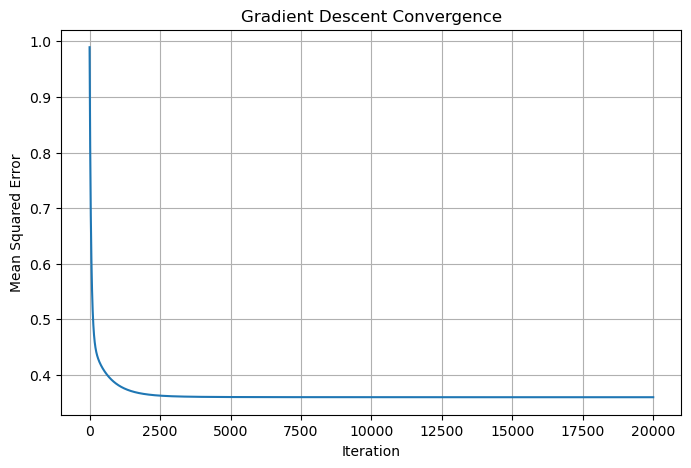

Convergence plot saved successfully!


In [28]:
import os

# Create a folder for project results
os.makedirs("results", exist_ok=True)

# Plot and save the cost convergence graph
plt.figure(figsize=(8, 5))
plt.plot(cost_history)

plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Convergence")
plt.grid(True)

plt.savefig("results/cost_convergence.png", dpi=300, bbox_inches="tight")
plt.show()

print("Convergence plot saved successfully!")

In [29]:
# Select median_income as the single feature
X_single = df[["median_income"]].to_numpy(dtype=float)

# Target: median house value
y_single = df["median_house_value"].to_numpy(dtype=float)

# Split into training and testing sets
X_single_train, X_single_test, y_single_train, y_single_test = train_test_split(
    X_single,
    y_single,
    test_size=0.2,
    random_state=42
)

print("Single-feature training shape:", X_single_train.shape)
print("Single-feature testing shape:", X_single_test.shape)

Single-feature training shape: (16512, 1)
Single-feature testing shape: (4128, 1)


In [30]:
# Calculate feature statistics using training data only
X_single_mean = np.mean(X_single_train, axis=0)
X_single_std = np.std(X_single_train, axis=0)

X_single_std[X_single_std == 0] = 1

# Standardize input features
X_single_train_scaled = (X_single_train - X_single_mean) / X_single_std
X_single_test_scaled = (X_single_test - X_single_mean) / X_single_std

# Standardize target using training data only
y_single_mean = np.mean(y_single_train)
y_single_std = np.std(y_single_train)

y_single_train_scaled = (y_single_train - y_single_mean) / y_single_std
y_single_test_scaled = (y_single_test - y_single_mean) / y_single_std

print("Training feature mean:", np.round(np.mean(X_single_train_scaled, axis=0), 4))
print("Training feature std:", np.round(np.std(X_single_train_scaled, axis=0), 4))
print("Training target mean:", round(np.mean(y_single_train_scaled), 4))
print("Training target std:", round(np.std(y_single_train_scaled), 4))

Training feature mean: [-0.]
Training feature std: [1.]
Training target mean: -0.0
Training target std: 1.0


In [31]:
# Train single-feature linear regression
theta_single, cost_history_single = gradient_descent(
    X_single_train_scaled,
    y_single_train_scaled,
    learning_rate=0.01,
    iterations=20000
)

print("Single-feature training completed!")
print("Initial cost:", cost_history_single[0])
print("Final cost:", cost_history_single[-1])
print("Number of parameters:", len(theta_single))

Single-feature training completed!
Initial cost: 0.9905078445818172
Final cost: 0.5230072654179475
Number of parameters: 2


In [33]:
# Predict on the scaled test features
y_single_pred_scaled = hypothesis(X_single_test_scaled, theta_single)

# Convert predictions back to original house-price units
y_single_pred = (
    y_single_pred_scaled * y_single_std + y_single_mean
)

# Calculate test MSE and RMSE manually
single_test_mse = np.mean((y_single_test - y_single_pred) ** 2)
single_test_rmse = np.sqrt(single_test_mse)

# Calculate R² manually
single_ss_res = np.sum((y_single_test - y_single_pred) ** 2)
single_ss_tot = np.sum(
    (y_single_test - np.mean(y_single_test)) ** 2
)

single_test_r2 = 1 - single_ss_res / single_ss_tot

print("SINGLE-FEATURE MODEL")
print(f"Test MSE:  {single_test_mse:.2f}")
print(f"Test RMSE: {single_test_rmse:.2f}")
print(f"Test R²:   {single_test_r2:.6f}")

SINGLE-FEATURE MODEL
Test MSE:  7091157771.77
Test RMSE: 84209.01
Test R²:   0.458859


## Results and Conclusion

### Dataset
- Dataset: California Housing
- Total samples: 20,640
- Training samples: 16,512
- Test samples: 4,128
- Train/test split: 80/20

### Multiple Linear Regression
- Implementation: NumPy from scratch
- Input features: 8
- Parameters: 9 (8 weights + 1 bias)
- Gradient descent iterations: 20,000
- Learning rate: 0.01
- Test MSE: 5,053,696,426.68
- Test RMSE: 71,089.36
- Test R²: 0.614342

### Simple Linear Regression
- Input feature: median_income
- Parameters: 2 (1 weight + 1 bias)
- Gradient descent iterations: 20,000
- Learning rate: 0.01
- Test MSE: 7,091,157,771.77
- Test RMSE: 84,209.01
- Test R²: 0.458859

### Conclusion
Linear regression was implemented from scratch using NumPy, including the hypothesis function, mean squared error cost function, and gradient descent optimization. Both simple and multiple linear regression were tested on the California Housing dataset. The multiple-feature model performed better than the single-feature model. Its performance was also compared with scikit-learn's LinearRegression implementation.

In [1]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current folder:
/Users/hemantsharma/Desktop/linear-regression-from-scratch

Files and folders here:
['anaconda_projects', 'results', '.virtual_documents', '.ipynb_checkpoints', 'linear_regression.ipynb']


In [2]:
import os

print(os.listdir("results"))

['cost_convergence.png']


In [3]:
readme_content = r"""# Linear Regression from Scratch using NumPy

## Overview
This project implements simple and multiple linear regression from scratch using NumPy.
It demonstrates the hypothesis function, mean squared error (MSE), gradient descent,
and manual evaluation of predictions.

## Dataset
- Dataset: California Housing
- Total samples: 20,640
- Input features for multiple regression: 8
- Training samples: 16,512
- Test samples: 4,128
- Split: 80% training, 20% testing

Missing values in `total_bedrooms` were replaced with the training-independent
column median before splitting. Numerical input features were standardized using
statistics calculated from the training set only. The target was also standardized
using training-set statistics for stable gradient descent.

## Mathematical Implementation

### Hypothesis Function
The model predicts the target using:

h_theta(X) = X theta

A column of ones is added to X to learn the bias (intercept).

### Mean Squared Error
The cost function is:

J(theta) = (1/m) * sum((prediction - actual)^2)

### Gradient Descent
Parameters are updated using:

theta = theta - learning_rate * gradient

The gradient is calculated using NumPy matrix operations. The cost is recorded
at every iteration to visualize convergence.

## Results

### Multiple Linear Regression
- Features: 8
- Parameters: 9 (8 weights + bias)
- Learning rate: 0.01
- Iterations: 20,000
- Test MSE: 5,053,696,426.68
- Test RMSE: 71,089.36
- Test R²: 0.614342

### Simple Linear Regression
- Feature: `median_income`
- Parameters: 2 (1 weight + bias)
- Learning rate: 0.01
- Iterations: 20,000
- Test MSE: 7,091,157,771.77
- Test RMSE: 84,209.01
- Test R²: 0.458859

### Scikit-learn Comparison
The multiple regression model was compared with scikit-learn's `LinearRegression`
on the same train/test split.

| Metric | NumPy implementation | Scikit-learn |
|---|---:|---:|
| Test MSE | 5,053,696,426.68 | 5,059,928,371.17 |
| Test R² | 0.614342 | 0.613866 |

The implementations produce similar test metrics. Gradient descent is an iterative
optimization method, so its parameters may differ slightly from the least-squares
solution computed by scikit-learn.

## Cost Convergence
The plot below shows the cost decreasing during gradient descent training.

![Gradient Descent Convergence](results/cost_convergence.png)

## Technologies
- Python
- NumPy
- Pandas
- Matplotlib
- scikit-learn (train/test split and final comparison only)

## How to Run
1. Clone or download this repository.
2. Install the required packages.
3. Open `linear_regression.ipynb` in Jupyter Notebook.
4. Run the notebook cells in order.

## Dependencies
- numpy
- pandas
- matplotlib
- scikit-learn

## Conclusion
This project demonstrates how linear regression works internally by implementing
the prediction function, cost function, and gradient descent without using
scikit-learn for model training.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [4]:
requirements = """numpy
pandas
matplotlib
scikit-learn
"""

with open("requirements.txt", "w", encoding="utf-8") as file:
    file.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [5]:
import os

print("Project folder contents:")
for item in sorted(os.listdir(".")):
    print(item)

print("\nResults folder contents:")
print(os.listdir("results"))

Project folder contents:
.ipynb_checkpoints
.virtual_documents
README.md
anaconda_projects
linear_regression.ipynb
requirements.txt
results

Results folder contents:
['cost_convergence.png']
